In [4]:
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that hand and JAX agree to ~1e-15
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sea
from plot_colors import *
set_style()

from _Part_a import ReLU, LeakyReLU, Sigmoid, Identity
from optimizer import Adam, train
from neural_network import NeuralNetwork
from general_functions import RungeData, Scaler, save_best_lr, load_best_lr, FIG_DIR
import time

In [5]:
"""Getting and scaling the data"""
data = RungeData()

X_train, X_test, y_train, y_test = data.split(data.nn_features())
scaler = Scaler().fit(X_train, y_train)

X_train_s, y_train_s = scaler.transform(X_train, y_train)
X_test_s, y_test_s = scaler.transform(X_test, y_test)

y_train_s = y_train_s.reshape(-1, 1)
y_test_s = y_test_s.reshape(-1, 1)

ReLU          : best gamma = 1.0e-02, test MSE = 0.0157
LeakyReLU     : best gamma = 1.0e-02, test MSE = 0.0158


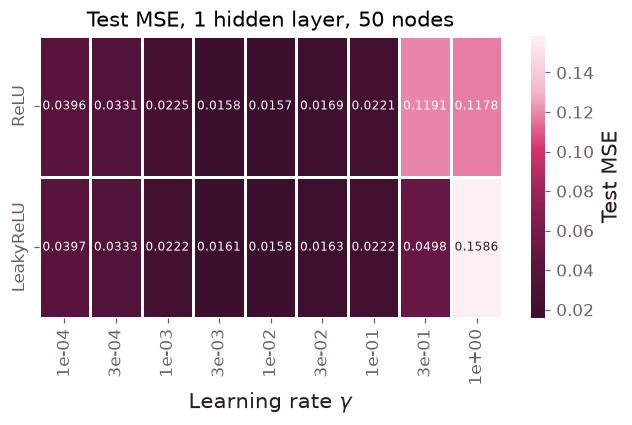

In [6]:
"""Find the best learning rates for ReLU and LeakyReLU as done in part b using
the same seed (2026), batch_size, nodes and hidden layers (16, 50 and 1)"""
gammas = np.logspace(-4, 0, 9)
batch_size = 16
epochs = 500


ReLUs = {'ReLU': ReLU(), 'LeakyReLU': LeakyReLU()}
results = np.zeros((len(ReLUs), len(gammas)))

for i, (name, activation) in enumerate(ReLUs.items()):
    for j, gamma in enumerate(gammas):
        nn = NeuralNetwork(1, [50, 1], [activation, Identity()])
        hist = train(nn, X_train_s, y_train_s, Adam(gamma), epochs=epochs, 
                     batch_size=batch_size, X_val = X_test_s, y_val = y_test_s)
        results[i, j] = hist['val'][-1]

#Finding the best learning rate
best = {}
for i, act_func in enumerate(ReLUs):
    j = np.nanargmin(results[i])
    best[act_func] = (gammas[j], results[i, j])
    save_best_lr(act_func, {'optimizer': 'SGD + Adam', 'best_lr': gammas[j], 'test_mse': results[i,j]})
    print(f"{act_func:14s}: best gamma = {gammas[j]:.1e}, test MSE = {results[i, j]:.4f}")


#Plotting heatmap for learningrate sweep
fig, ax = plt.subplots(figsize = (6, 4))
results_plot = np.where(np.isfinite(results), results, np.nan)
sea.heatmap(results_plot, ax = ax, cmap = MSE_CMAP, annot = True, fmt = ".4f",
            annot_kws = {"size": 8}, linewidths = 1.8, linecolor = "white",
            xticklabels = [f"{g:.0e}" for g in gammas], yticklabels = list(ReLUs),
            cbar_kws = {"label": "Test MSE"})

ax.set_xlabel(r"Learning rate $\gamma$")
ax.grid(False)
ax.set_title("Test MSE, 1 hidden layer, 50 nodes")
fig.tight_layout()
plt.savefig(FIG_DIR / "Part_c_heatmap_lrs.pdf")
plt.show()

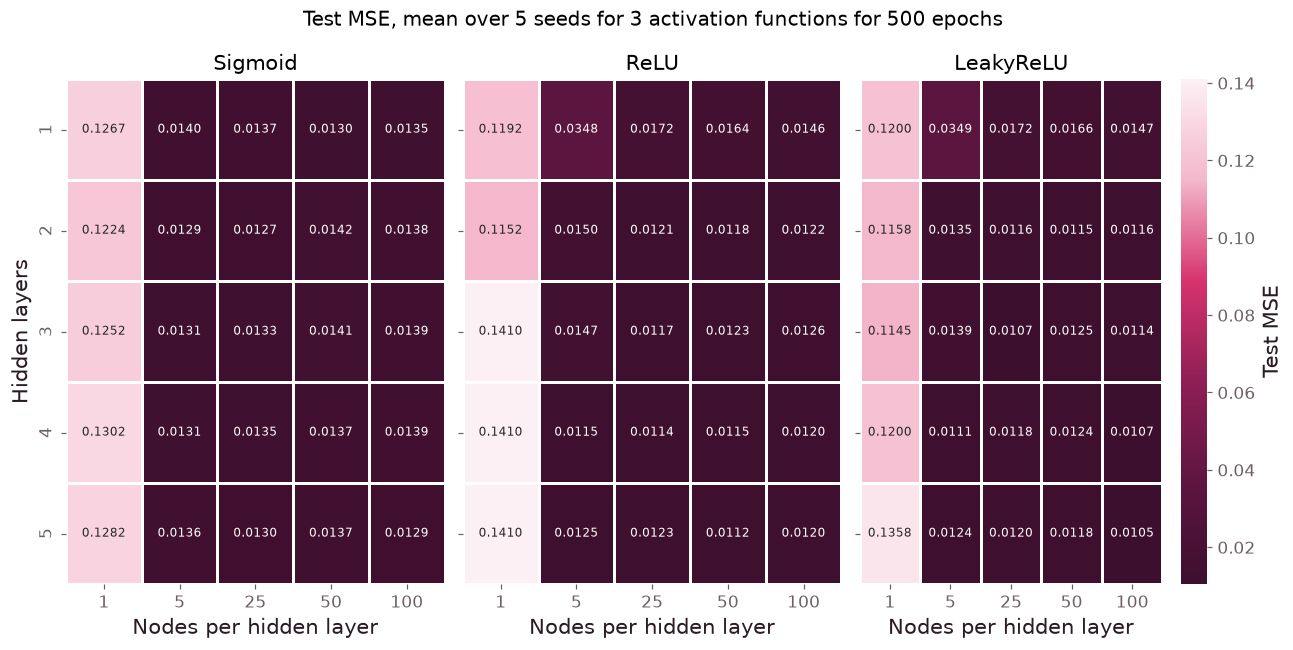

Sigmoid     1 x 1    : Train MSE = 0.0829 $\pm$ 0.0089 Test MSE = 0.1267 $\pm$ 0.0116  Time = 0.447 $\pm 0.032  Best epoch 488
Sigmoid     1 x 5    : Train MSE = 0.0164 $\pm$ 0.0005 Test MSE = 0.0140 $\pm$ 0.0011  Time = 0.524 $\pm 0.021  Best epoch 500
Sigmoid     1 x 25   : Train MSE = 0.0156 $\pm$ 0.0003 Test MSE = 0.0137 $\pm$ 0.0010  Time = 0.667 $\pm 0.081  Best epoch 499
Sigmoid     1 x 50   : Train MSE = 0.0150 $\pm$ 0.0002 Test MSE = 0.0130 $\pm$ 0.0004  Time = 0.550 $\pm 0.013  Best epoch 500
Sigmoid     1 x 100  : Train MSE = 0.0155 $\pm$ 0.0008 Test MSE = 0.0135 $\pm$ 0.0009  Time = 0.522 $\pm 0.030  Best epoch 499
Sigmoid     2 x 1    : Train MSE = 0.0777 $\pm$ 0.0055 Test MSE = 0.1224 $\pm$ 0.0076  Time = 0.495 $\pm 0.003  Best epoch 496
Sigmoid     2 x 5    : Train MSE = 0.0157 $\pm$ 0.0006 Test MSE = 0.0129 $\pm$ 0.0002  Time = 0.554 $\pm 0.011  Best epoch 500
Sigmoid     2 x 25   : Train MSE = 0.0144 $\pm$ 0.0004 Test MSE = 0.0127 $\pm$ 0.0003  Time = 0.783 $\pm 0.077 

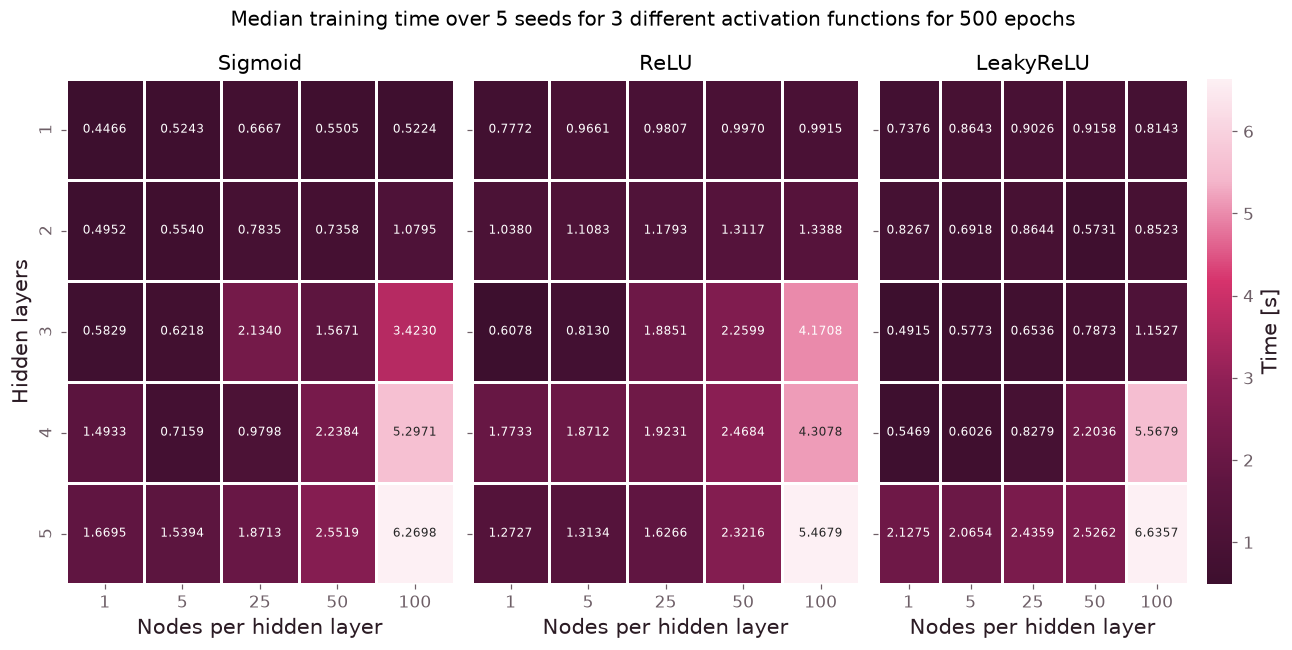

In [8]:
"""We now test different activation functions and depths of the nn using the best lrs for each
activation function"""
all_act_funcs ={'Sigmoid': Sigmoid(), 'ReLU': ReLU(), 'LeakyReLU': LeakyReLU()}
best_lrs_all = [load_best_lr(name)['best_lr'] for name in all_act_funcs]
seeds = [21, 36, 67, 420, 2026]             #test for different seeds

n_layers = [1, 2, 3, 4, 5]
n_nodes = [1, 5, 25, 50, 100]

#Keep same format (e.g '1 x 50': [50, 1]) but for all layers and nodes
networks_sizes = {f' {layers} x {nodes}': [nodes] * layers + [1] for layers in n_layers for nodes in n_nodes }

train_mse = np.zeros((len(all_act_funcs), len(networks_sizes), len(seeds)))
test_mse = np.zeros_like(train_mse)
fit_time = np.zeros_like(train_mse)

test_curves = np.zeros((len(all_act_funcs), len(networks_sizes), len(seeds), epochs))


for i, (_, act) in enumerate(all_act_funcs.items()):
    gamma = best_lrs_all[i]
    for j, (__, sizes) in enumerate(networks_sizes.items()):
        activations = [act] * (len(sizes) - 1 ) + [Identity()]
        for k, seed in enumerate(seeds):
            nn = NeuralNetwork(1, sizes, activations, seed=seed)

            time_start = time.perf_counter()
            hist = train(nn, X_train_s, y_train_s, Adam(gamma), epochs=epochs, batch_size=batch_size, 
                         seed=seed, X_val = X_test_s, y_val = y_test_s)
            time_end = time.perf_counter()

            train_mse[i, j, k] = hist['train'][-1]
            test_mse[i, j, k] = hist['val'][-1]
            fit_time[i, j, k] = time_end - time_start
            test_curves[i, j, k] = hist['val']

train_mean, train_std = train_mse.mean(axis=2), train_mse.std(axis=2)
test_mean, test_std = test_mse.mean(axis=2), test_mse.std(axis=2)

#reshape into 4x4 matrix 
shape = (len(all_act_funcs), len(n_layers), len(n_nodes))
test_mean_grid = test_mean.reshape(shape)

vmin, vmax = np.nanmin(test_mean_grid), np.nanmax(test_mean_grid) 

fig, axes = plt.subplots(1, len(all_act_funcs), figsize=(12, 6), sharey=True)

for i, (ax, name) in enumerate(zip(axes, all_act_funcs)):
    sea.heatmap(test_mean_grid[i], ax=ax, cmap=MSE_CMAP, annot=True, fmt='.4f',
            vmin = vmin, vmax = vmax,
            annot_kws = {"size": 8}, linewidths = 1.8, linecolor = "white",
            xticklabels = n_nodes, yticklabels = n_layers,
            cbar=(i == len(all_act_funcs) - 1), cbar_kws={"label": "Test MSE"})
    ax.set_title(name)
    ax.set_xlabel('Nodes per hidden layer')
    ax.grid(False)

axes[0].set_ylabel('Hidden layers')
fig.suptitle(f'Test MSE, mean over {len(seeds)} seeds for 3 activation functions for {epochs} epochs')
fig.tight_layout()
plt.savefig(FIG_DIR / "Part_c_heatmap_mses.pdf")
plt.show()

#Print every train and test MSE and the training time for each activation 
# function for each hidden layer and number of nodes 
mean_curves = test_curves.mean(axis=2)
time_median = np.median(fit_time, axis=2)
time_std = fit_time.std(axis=2)

for i, act_name in enumerate(all_act_funcs):
    for j, size_name in enumerate(networks_sizes):
        curve = mean_curves[i, j]
        best_epoch = np.argmin(curve)
        print(f'{act_name:10s} {size_name:10s}:'
              rf' Train MSE = {train_mean[i, j]:.4f} $\pm$ {train_std[i, j]:.4f}'
              rf' Test MSE = {test_mean[i, j]:.4f} $\pm$ {test_std[i, j]:.4f}',
              rf' Time = {time_median[i, j]:.3f} $\pm {time_std[i, j]:.3f}',
              rf' Best epoch {best_epoch + 1}')

#Heatmap for how long it takes for each network size for each activation function
time_grid = time_median.reshape(shape)

fig, axes = plt.subplots(1, len(all_act_funcs), figsize=(12, 6), sharey=True)
for i, (ax, name) in enumerate(zip(axes, all_act_funcs)):
    sea.heatmap(time_grid[i], ax=ax, cmap=MSE_CMAP, annot=True, fmt='.4f', 
                annot_kws={"size": 8}, linewidths=1.8, linecolor="white",
                xticklabels=n_nodes, yticklabels=n_layers,
                cbar=(i == len(all_act_funcs) - 1), cbar_kws={"label": "Time [s]"})
    ax.set_title(name)
    ax.set_xlabel('Nodes per hidden layer')
    ax.grid(False)
axes[0].set_ylabel('Hidden layers')
fig.suptitle(f'Median training time over {len(seeds)} seeds for 3 different activation functions for {epochs} epochs')
fig.tight_layout()
plt.savefig(FIG_DIR / "Part_c_heatmap_mses_time.pdf")
plt.show()

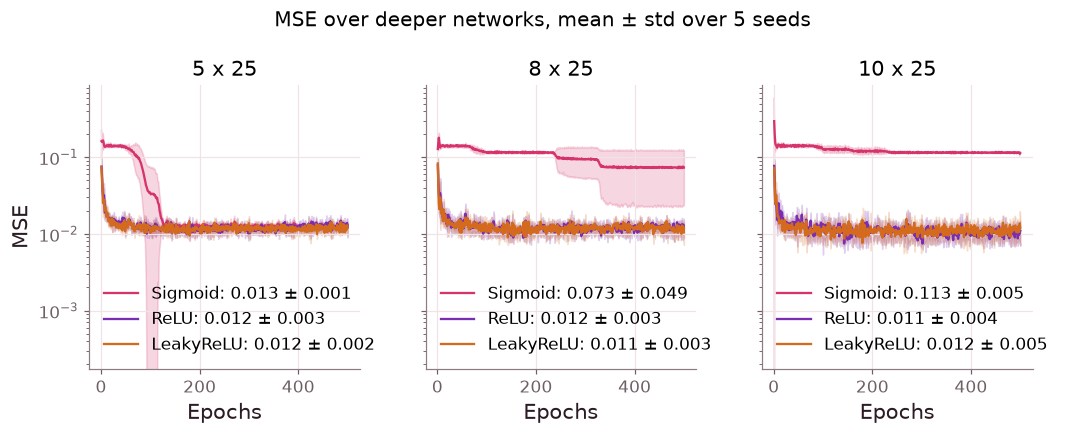

In [9]:
"""Look at deeper networks to see how Sigmoid vanishes"""
n_layers_deeper = [5, 8, 10]
n_nodes_deeper = [25]
deeper_sizes = {f'{layers} x {nodes}': [nodes] * layers + [1] for layers in n_layers_deeper for nodes in n_nodes_deeper}

deeper_test = np.zeros((len(all_act_funcs), len(deeper_sizes), len(seeds)))
deeper_curves = np.zeros((len(all_act_funcs), len(deeper_sizes), len(seeds), epochs))

#Same as above but for depeer network now
for i, (_, act) in enumerate(all_act_funcs.items()):
    gamma = best_lrs_all[i]
    for j, (_, sizes) in enumerate(deeper_sizes.items()):
        activations = [act] * (len(sizes) - 1) + [Identity()]
        for k, seed in enumerate(seeds):
            nn = NeuralNetwork(1, sizes, activations, seed=seed)
            hist = train(nn, X_train_s, y_train_s, Adam(gamma), epochs=epochs, batch_size=batch_size,
                         seed=seed, X_val=X_test_s, y_val=y_test_s)
            deeper_test[i, j, k] = hist['val'][-1]
            deeper_curves[i, j, k] = hist['val']

#Plot the graphs LLM Assisted
fig, axes = plt.subplots(1, len(deeper_sizes), figsize=(10, 4), sharey=True)
for j, (ax, size_name) in enumerate(zip(axes, deeper_sizes)):
    for i, act_name in enumerate(all_act_funcs):
        mean, std = deeper_curves[i, j].mean(axis=0), deeper_curves[i, j].std(axis=0)
        ax.plot(np.arange(1, epochs + 1), mean, color=ACTIVATION_COLORS[act_name],
                label=f'{act_name}: {deeper_test[i, j].mean():.3f} $\\pm$ {deeper_test[i, j].std():.3f}')
        ax.fill_between(np.arange(1, epochs + 1), mean - std, mean + std, color=ACTIVATION_COLORS[act_name], alpha=0.2)
    ax.set_yscale('log')
    ax.set_title(size_name)
    ax.set_xlabel('Epochs')
    ax.legend()
axes[0].set_ylabel('MSE')
fig.suptitle(f'MSE over deeper networks, mean $\\pm$ std over {len(seeds)} seeds')
fig.tight_layout()
plt.savefig(FIG_DIR / "Part_c_deeper_networks_curves.pdf")
plt.show()

Sigmoid   : lowest test MSE 0.0093 at epoch 3950, At epoch 4000: train MSE 0.0131, test MSE0.0095
ReLU      : lowest test MSE 0.0099 at epoch 275, At epoch 4000: train MSE 0.0106, test MSE0.0142
LeakyReLU : lowest test MSE 0.0104 at epoch 275, At epoch 4000: train MSE 0.0113, test MSE0.0107


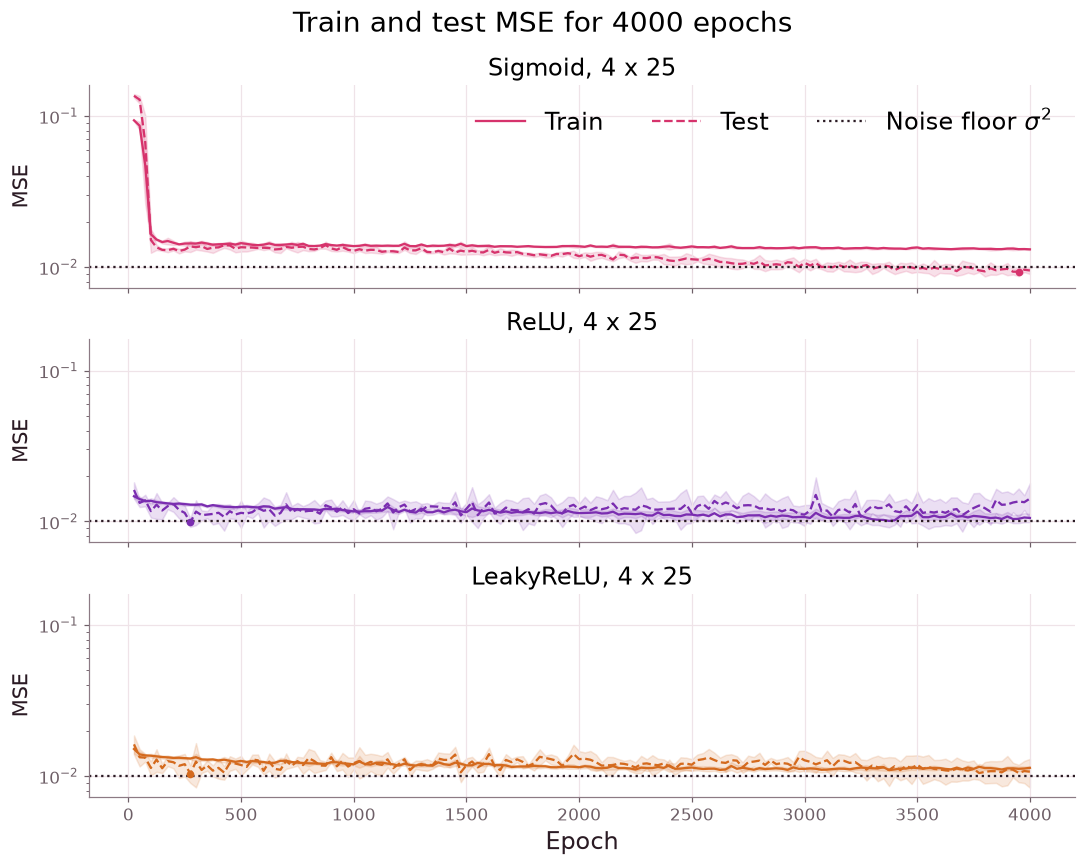

In [10]:
"""We now want to check for overfitting, thus increase the number of epochs and 
use the big network size that gave the lowest mse for most of most of the activation functions"""

big_epochs = 4000
eval_every = 25
big_network_size = [25, 25, 25, 25, 1]
n_points = big_epochs // eval_every

train_mse_long = np.zeros((len(all_act_funcs), n_points, len(seeds)))
test_mse_long = np.zeros_like(train_mse_long)

for i, (_, act) in enumerate(all_act_funcs.items()):
    gamma = best_lrs_all[i]
    activations = [act] * (len(big_network_size) - 1 ) + [Identity()]
    for k, seed in enumerate(seeds):
        nn = NeuralNetwork(1, big_network_size, activations, seed=seed)
        hist = train(nn, X_train_s, y_train_s, Adam(gamma), epochs=big_epochs, batch_size=batch_size, seed=seed, X_val = X_test_s, y_val = y_test_s, eval_every=eval_every)

        train_mse_long[i, :, k] = hist['train']
        test_mse_long[i, :, k] = hist['val']

long_ep = np.array(hist['epoch'])

"""Plot of train and test MSE against epoch, one row per activation, LLM Assisted"""
fig, axes = plt.subplots(len(all_act_funcs), 1, figsize=(10,8), sharex=True, sharey=True)

for ax, (i, name) in zip(axes.ravel(), enumerate(all_act_funcs)):
    color = ACTIVATION_COLORS[name]
    train_mean_l, train_std_l = train_mse_long[i].mean(axis=-1), train_mse_long[i].std(axis=-1)
    test_mean_l, test_std_l = test_mse_long[i].mean(axis=-1), test_mse_long[i].std(axis=-1)

    ax.plot(long_ep, train_mean_l, TRAIN_LS, color=color, label='Train')
    ax.fill_between(long_ep, train_mean_l - train_std_l, train_mean_l + train_std_l, color=color, alpha=0.15)
    ax.plot(long_ep, test_mean_l, VAL_LS, color=color, label='Test')
    ax.fill_between(long_ep, test_mean_l - test_std_l, test_mean_l + test_std_l, color=color, alpha=0.15)
    ax.axhline(data.noise**2, color=COLORS['text'], ls=':', label=r'Noise floor $\sigma^2$')

    best_index = np.argmin(test_mean_l)     # mark the lowest test MSE
    print(f'{name:10s}: lowest test MSE {test_mean_l[best_index]:.4f} at epoch {long_ep[best_index]}, '
      f'At epoch {long_ep[-1]}: train MSE {train_mean_l[-1]:.4f}, test MSE{test_mean_l[-1]:.4f}')
    ax.plot(long_ep[best_index], test_mean_l[best_index], 'o', color=color, ms=4)

    ax.set_title(f'{name}, {len(big_network_size) - 1} x {big_network_size[0]}', fontsize=16)    
    ax.set_ylabel('MSE')
    ax.set_yscale('log')

axes[-1].set_xlabel('Epoch', fontsize=16)
axes[0].legend(loc='upper right', ncol=3, fontsize=16)
fig.suptitle(f'Train and test MSE for {big_epochs} epochs', fontsize=18)
plt.savefig(FIG_DIR / "Part_c_longtrain_4x25.pdf")
fig.tight_layout()

Sigmoid   : lowest test MSE 0.0103 at epoch 1175, At epoch 4000: train MSE 0.0095, test MSE0.0276
ReLU      : lowest test MSE 0.0090 at epoch 2200, At epoch 4000: train MSE 0.0105, test MSE0.0103
LeakyReLU : lowest test MSE 0.0100 at epoch 425, At epoch 4000: train MSE 0.0119, test MSE0.0143


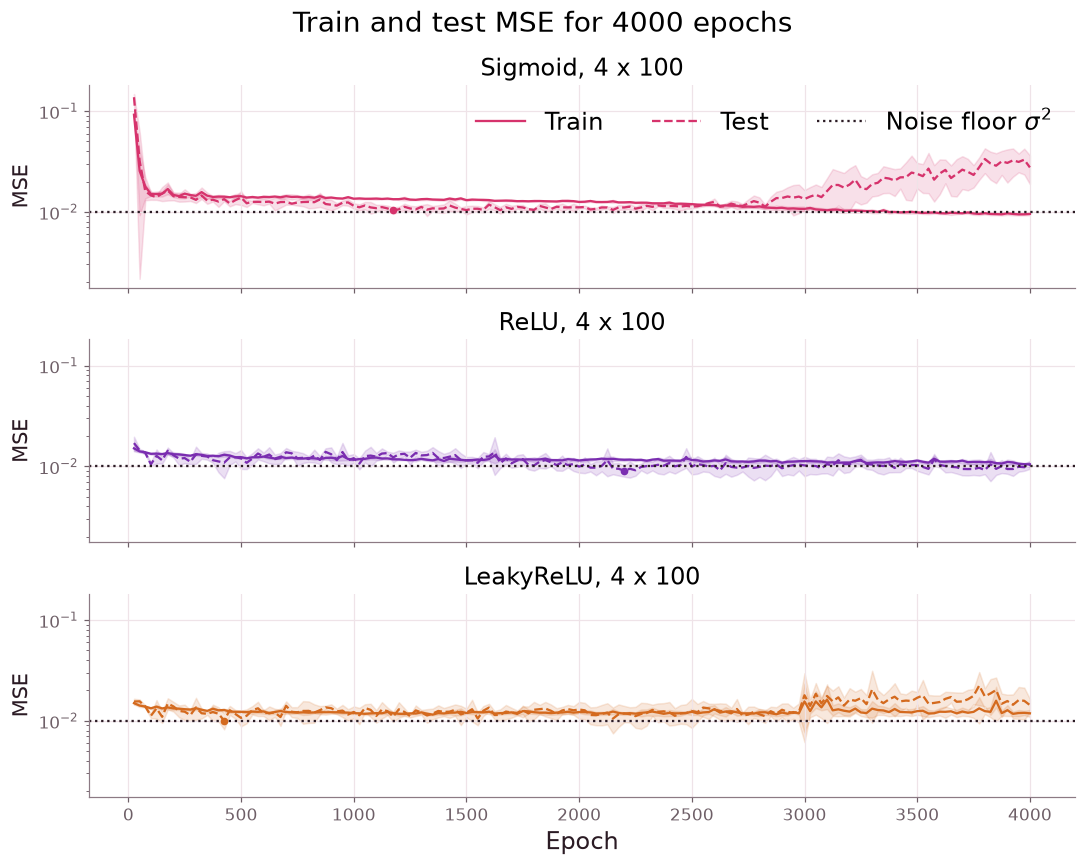

In [11]:
"""Check for overfitting if we increase the number of nodes"""
big_network_size_100 = [100, 100, 100, 100, 1]
n_points = big_epochs // eval_every

train_mse_long_100 = np.zeros((len(all_act_funcs), n_points, len(seeds)))
test_mse_long_100 = np.zeros_like(train_mse_long_100)

for i, (_, act) in enumerate(all_act_funcs.items()):
    gamma = best_lrs_all[i]
    activations = [act] * (len(big_network_size_100) - 1 ) + [Identity()]
    for k, seed in enumerate(seeds):
        nn = NeuralNetwork(1, big_network_size_100, activations, seed=seed)
        hist = train(nn, X_train_s, y_train_s, Adam(gamma), epochs=big_epochs, batch_size=batch_size, 
                     seed=seed, X_val = X_test_s, y_val = y_test_s, eval_every=eval_every)

        train_mse_long_100[i, :, k] = hist['train']
        test_mse_long_100[i, :, k] = hist['val']

long_ep = np.array(hist['epoch'])

"""Plot of train and test MSE against epoch, one row per activation, LLM Assisted"""
fig, axes = plt.subplots(len(all_act_funcs), 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, (i, name) in zip(axes.ravel(), enumerate(all_act_funcs)):
    color = ACTIVATION_COLORS[name]
    train_mean_l_100, train_std_l_100 = train_mse_long_100[i].mean(axis=-1), train_mse_long_100[i].std(axis=-1)
    test_mean_l_100, test_std_l_100 = test_mse_long_100[i].mean(axis=-1), test_mse_long_100[i].std(axis=-1)

    ax.plot(long_ep, train_mean_l_100, TRAIN_LS, color=color, label='Train')
    ax.fill_between(long_ep, train_mean_l_100 - train_std_l_100, train_mean_l_100 + train_std_l_100, color=color, alpha=0.15)
    ax.plot(long_ep, test_mean_l_100, VAL_LS, color=color, label='Test')
    ax.fill_between(long_ep, test_mean_l_100 - test_std_l_100, test_mean_l_100 + test_std_l_100, color=color, alpha=0.15)
    ax.axhline(data.noise**2, color=COLORS['text'], ls=':', label=r'Noise floor $\sigma^2$')

    best_idx = np.argmin(test_mean_l_100)     # mark the lowest test MSE
    print(f'{name:10s}: lowest test MSE {test_mean_l_100[best_idx]:.4f} at epoch {long_ep[best_idx]}, '
      f'At epoch {long_ep[-1]}: train MSE {train_mean_l_100[-1]:.4f}, test MSE{test_mean_l_100[-1]:.4f}')
    ax.plot(long_ep[best_idx], test_mean_l_100[best_idx], 'o', color=color, ms=4)

    ax.set_title(f'{name}, {len(big_network_size_100) - 1} x {big_network_size_100[0]}', fontsize=16)    
    ax.set_ylabel('MSE')
    ax.set_yscale('log')

axes[-1].set_xlabel('Epoch', fontsize=16)
axes[0].legend(loc='upper right', ncol=3, fontsize=16)
fig.suptitle(f'Train and test MSE for {big_epochs} epochs', fontsize=18)
fig.tight_layout()
plt.savefig(FIG_DIR / "Part_c_longtrain_4x100.pdf")
plt.show()